# 02 · Training – data pipeline, baseline CNN, transfer learning

Builds on the EDA decisions: class weights, flips + brightness/contrast augmentation,
256 px input, recall-focused evaluation.


## Setup

In [1]:
import shutil
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import tensorflow as tf

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    DRIVE_DIR = Path("/content/drive/MyDrive/deck-crack-detection")
    DATA_DIR = Path("/content/data/processed")  # fast local disk of the Colab machine

    if not DATA_DIR.exists():  # unzip only once per session
        print("Unzipping data ...")
        shutil.unpack_archive(DRIVE_DIR / "processed.zip", DATA_DIR)

    FIG_DIR = DRIVE_DIR / "figures"  # saved on Drive → survives the session
    MODEL_DIR = DRIVE_DIR / "models"
else:
    ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
    DATA_DIR = ROOT / "data" / "processed"
    FIG_DIR = ROOT / "reports" / "figures"
    MODEL_DIR = ROOT / "models"

FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
assert (DATA_DIR / "train").exists(), f"No train folder in {DATA_DIR}"

# Constants
SEED = 42
IMAGE_SIZE = (256, 256)
BATCH_SIZE = 32
CLASS_NAMES = ["uncracked", "cracked"]  # index 1 = cracked (positive class)

tf.keras.utils.set_random_seed(SEED)

print("Running on:", "Colab" if IN_COLAB else "local")
print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))
print("Data:", DATA_DIR)


Mounted at /content/drive
Unzipping data ...
Running on: Colab
TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Data: /content/data/processed


## Load the data

In [2]:
def load_split(split, shuffle):
    """Create a batched dataset for one split with fixed label order."""
    return tf.keras.utils.image_dataset_from_directory(
        DATA_DIR / split,
        class_names=CLASS_NAMES,
        label_mode="binary",
        image_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED,
    )


train_ds = load_split("train", shuffle=True)
val_ds = load_split("val", shuffle=False)
test_ds = load_split("test", shuffle=False)

Found 9533 files belonging to 2 classes.
Found 2044 files belonging to 2 classes.
Found 2043 files belonging to 2 classes.


## Check one batch

In [3]:
images, labels = next(iter(train_ds))

print("Images:", images.shape, images.dtype)
print("Labels:", labels.shape, labels.dtype)
print("Pixel range:", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))
print("Cracked in this batch:", int(tf.reduce_sum(labels)), "of", len(labels))

Images: (32, 256, 256, 3) <dtype: 'float32'>
Labels: (32, 1) <dtype: 'float32'>
Pixel range: 0.0 to 255.0
Cracked in this batch: 2 of 32


## Speed up loading

In [4]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)

## Augmentation

In [5]:
data_augmentation = tf.keras.Sequential(
    [
        tf.keras.layers.RandomFlip("horizontal_and_vertical", seed=SEED),
        tf.keras.layers.RandomBrightness(factor=0.2, value_range=(0, 255), seed=SEED),
        tf.keras.layers.RandomContrast(factor=0.2, seed=SEED),
    ],
    name="augmentation",
)

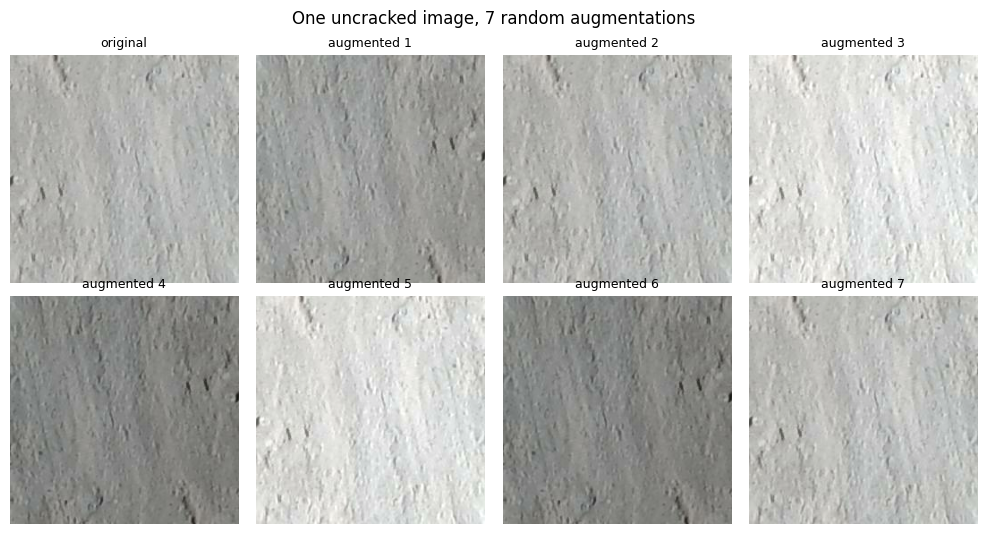

In [6]:
image = images[0]
label = CLASS_NAMES[int(labels[0, 0])]

fig, axes = plt.subplots(2, 4, figsize=(10, 5.4))

for i, ax in enumerate(axes.flat):
    shown = image if i == 0 else data_augmentation(image[tf.newaxis], training=True)[0]
    ax.imshow(np.clip(shown.numpy(), 0, 255).astype("uint8"))
    ax.set_title("original" if i == 0 else f"augmented {i}", fontsize=9)
    ax.axis("off")

fig.suptitle(f"One {label} image, 7 random augmentations")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_augmentation_examples.png", dpi=150, bbox_inches="tight")
plt.show()

- Augmentation check: flips + ±20% brightness/contrast produce realistic variations (shadow-like to sunlit);
  dark augmented images of both classes counteract the brightness bias found in the EDA.


## Model Builder


In [7]:
def build_cnn(name, batch_norm=False, filters=(16, 32, 64, 128), dropout=0.3):
    """Small CNN; optional batch normalisation after each convolution."""
    inputs = tf.keras.Input(shape=IMAGE_SIZE + (3,))
    x = data_augmentation(inputs)
    x = tf.keras.layers.Rescaling(1.0 / 255)(x)

    for n_filters in filters:
        x = tf.keras.layers.Conv2D(n_filters, 3, padding="same", use_bias=not batch_norm)(x)
        if batch_norm:
            x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Activation("relu")(x)
        x = tf.keras.layers.MaxPooling2D()(x)

    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(dropout)(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)

    return tf.keras.Model(inputs, outputs, name=name)


build_cnn("test", batch_norm=True).summary()

Model: "test"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 256, 256, 16)   │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256, 256, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256, 256, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 98,289 (383.94 KB)

 Trainable params: 97,809 (382.07 KB)

 Non-trainable params: 480 (1.88 KB)

##Class weights and compile helper

In [8]:
n_uncracked, n_cracked = 8116, 1417
n_total = n_uncracked + n_cracked
class_weight = {0: n_total / (2 * n_uncracked), 1: n_total / (2 * n_cracked)}
print({k: round(v, 2) for k, v in class_weight.items()})


def compile_model(model, learning_rate=1e-3):
    """Compile with Adam, binary cross-entropy and recall-focused metrics."""
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc"),
        ],
    )
    return model

{0: 0.59, 1: 3.36}


## Training helper

In [9]:
def train_model(model, epochs=40, patience=6):
    """Train with early stopping; save best model and history to Drive."""
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_pr_auc", mode="max", patience=patience, restore_best_weights=True
        ),
        tf.keras.callbacks.ModelCheckpoint(
            str(MODEL_DIR / f"{model.name}.keras"),
            monitor="val_pr_auc", mode="max", save_best_only=True,
        ),
        tf.keras.callbacks.CSVLogger(str(MODEL_DIR / f"{model.name}_history.csv")),
    ]
    return model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        class_weight=class_weight,
        callbacks=callbacks,
    )

## Train both models

In [10]:
experiments = {
    "cnn_v1": dict(batch_norm=False),
    "cnn_v2_bn": dict(batch_norm=True),
}

models, histories = {}, {}

for name, options in experiments.items():
    print(f"\n===== Training {name} =====")
    model = compile_model(build_cnn(name, **options))
    histories[name] = train_model(model)
    models[name] = model


===== Training cnn_v1 =====
Epoch 1/40
298/298 ━━━━━━━━━━━━━━━━━━━━ 42s 94ms/step - accuracy: 0.4728 - loss: 0.6929 - pr_auc: 0.1518 - precision: 0.1536 - recall: 0.5646 - val_accuracy: 0.1859 - val_loss: 0.6854 - val_pr_auc: 0.1539 - val_precision: 0.1534 - val_recall: 0.9901
Epoch 2/40
298/298 ━━━━━━━━━━━━━━━━━━━━ 13s 44ms/step - accuracy: 0.3506 - loss: 0.6875 - pr_auc: 0.1543 - precision: 0.1584 - recall: 0.7812 - val_accuracy: 0.1820 - val_loss: 0.6955 - val_pr_auc: 0.1530 - val_precision: 0.1531 - val_recall: 0.9934
Epoch 3/40
298/298 ━━━━━━━━━━━━━━━━━━━━ 13s 45ms/step - accuracy: 0.2778 - loss: 0.6884 - pr_auc: 0.1485 - precision: 0.1520 - recall: 0.8426 - val_accuracy: 0.2074 - val_loss: 0.6831 - val_pr_auc: 0.1554 - val_precision: 0.1562 - val_recall: 0.9836
Epoch 4/40
298/298 ━━━━━━━━━━━━━━━━━━━━ 14s 45ms/step - accuracy: 0.3701 - loss: 0.6911 - pr_auc: 0.1471 - precision: 0.1471 - recall: 0.6747 - val_accuracy: 0.1854 - val_loss: 0.6873 - val_pr_auc: 0.1494 - val_precision:

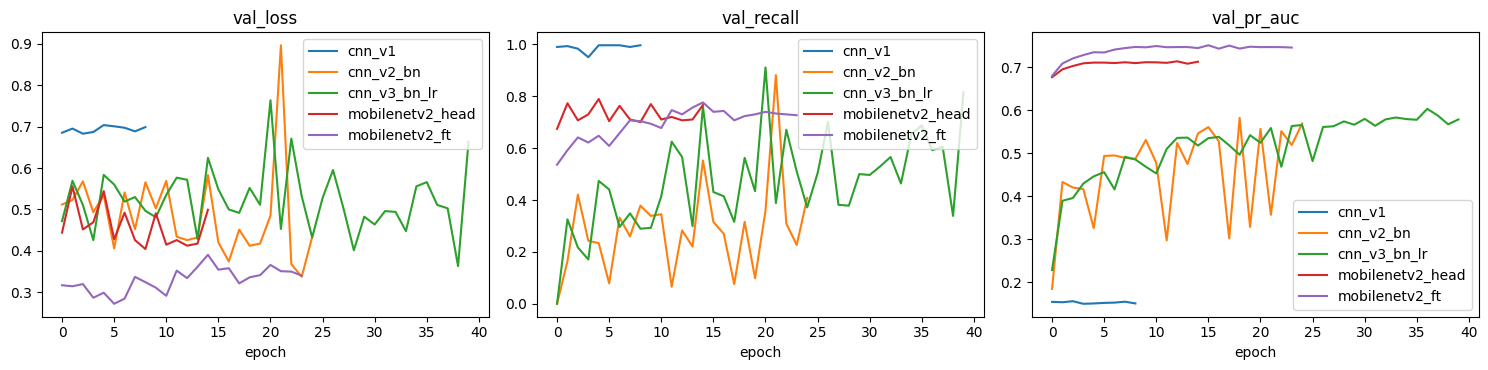

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

for name, history in histories.items():
    for ax, metric in zip(axes, ["val_loss", "val_recall", "val_pr_auc"]):
        ax.plot(history.history[metric], label=name)
        ax.set_title(metric)
        ax.set_xlabel("epoch")

for ax in axes:
    ax.legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "08_model_comparison_curves.png", dpi=150, bbox_inches="tight")
plt.show()

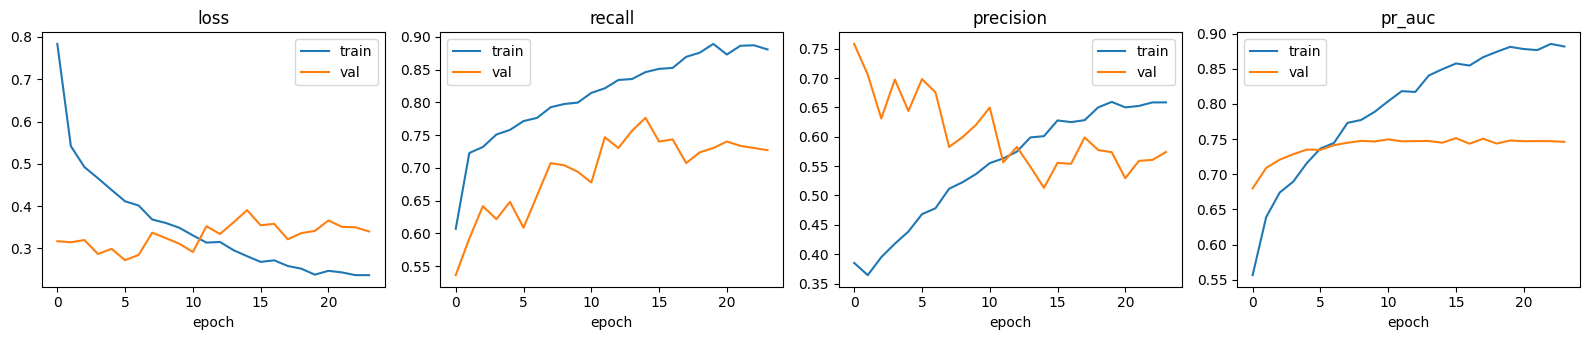

In [25]:
metrics_to_plot = ["loss", "recall", "precision", "pr_auc"]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, metric in zip(axes, metrics_to_plot):
    ax.plot(history.history[metric], label="train")
    ax.plot(history.history[f"val_{metric}"], label="val")
    ax.set_title(metric)
    ax.set_xlabel("epoch")
    ax.legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "07_baseline_learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

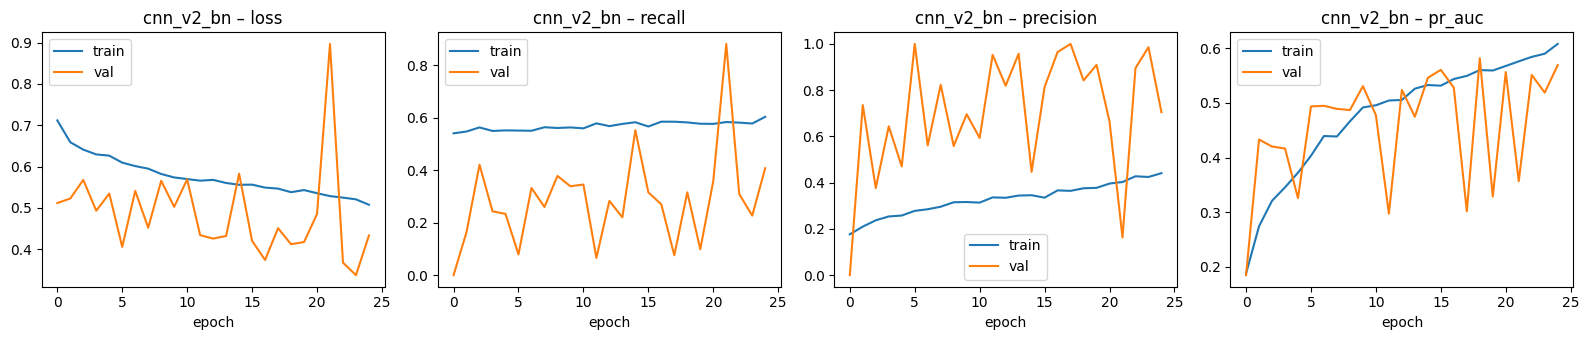

In [26]:
def plot_history(name, metrics=("loss", "recall", "precision", "pr_auc")):
    """Plot train vs validation curves for one trained model."""
    history = histories[name].history

    fig, axes = plt.subplots(1, len(metrics), figsize=(4 * len(metrics), 3.5))
    for ax, metric in zip(axes, metrics):
        ax.plot(history[metric], label="train")
        ax.plot(history[f"val_{metric}"], label="val")
        ax.set_title(f"{name} – {metric}")
        ax.set_xlabel("epoch")
        ax.legend()

    plt.tight_layout()
    plt.savefig(FIG_DIR / f"curves_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


plot_history("cnn_v2_bn")

In [27]:
rows = []
for name, model in models.items():
    results = model.evaluate(val_ds, return_dict=True, verbose=0)
    rows.append(
        {
            "model": name,
            "params": model.count_params(),
            "epochs_run": len(histories[name].history["loss"]),
            **{k: round(v, 3) for k, v in results.items()},
        }
    )

results_df = pd.DataFrame(rows).set_index("model")
results_df.to_csv(MODEL_DIR / "results_val.csv")
results_df


,params,epochs_run,accuracy,loss,pr_auc,precision,recall
model,,,,,,,
cnn_v1,97569,9,0.207,0.683,0.155,0.156,0.984
cnn_v2_bn,98289,25,0.889,0.412,0.582,0.842,0.316
cnn_v3_bn_lr,98289,40,0.851,0.511,0.603,0.499,0.592
mobilenetv2_ft,2259265,24,0.873,0.355,0.751,0.556,0.740


- **v1 (no BN):** stuck at chance level, predicts almost everything as cracked (accuracy 0.21 < 0.85 majority baseline).
  The same architecture reached 0.60 on the CPU run → without BN, training success depends on random initialisation.
- **v2 (BN):** learns reliably; BN adds only 720 parameters. Validation curve zigzags (PR-AUC 0.30–0.58).
- At threshold 0.5, v2 is conservative: precision 0.84 but recall only 0.32 → threshold tuning needed for safety.
- **Next:** lower learning rate + learning-rate reduction (v3) to stabilise training.


In [20]:
def train_model(model, epochs=40, patience=8, run_name=None):
    """Train with early stopping and LR reduction; save best model and history to Drive."""
    run_name = run_name or model.name
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_pr_auc", mode="max", patience=patience, restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_pr_auc", mode="max", factor=0.5, patience=3, min_lr=1e-7, verbose=1
        ),
        tf.keras.callbacks.ModelCheckpoint(
            str(MODEL_DIR / f"{run_name}.keras"),
            monitor="val_pr_auc", mode="max", save_best_only=True,
        ),
        tf.keras.callbacks.CSVLogger(str(MODEL_DIR / f"{run_name}_history.csv")),
    ]
    return model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        class_weight=class_weight,
        callbacks=callbacks,
    )

In [16]:
new_experiments = {
    "cnn_v3_bn_lr": dict(batch_norm=True, learning_rate=3e-4),
}

for name, options in new_experiments.items():
    options = dict(options)
    learning_rate = options.pop("learning_rate", 1e-3)

    print(f"\n===== Training {name} =====")
    model = compile_model(build_cnn(name, **options), learning_rate=learning_rate)
    histories[name] = train_model(model)
    models[name] = model


===== Training cnn_v3_bn_lr =====
Epoch 1/40
298/298 ━━━━━━━━━━━━━━━━━━━━ 31s 76ms/step - accuracy: 0.5658 - loss: 0.7082 - pr_auc: 0.1955 - precision: 0.1811 - recall: 0.5455 - val_accuracy: 0.8513 - val_loss: 0.4719 - val_pr_auc: 0.2280 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 3.0000e-04
Epoch 2/40
298/298 ━━━━━━━━━━━━━━━━━━━━ 16s 54ms/step - accuracy: 0.6053 - loss: 0.6691 - pr_auc: 0.2391 - precision: 0.2042 - recall: 0.5716 - val_accuracy: 0.8234 - val_loss: 0.5693 - val_pr_auc: 0.3893 - val_precision: 0.3882 - val_recall: 0.3257 - learning_rate: 3.0000e-04
Epoch 3/40
298/298 ━━━━━━━━━━━━━━━━━━━━ 16s 54ms/step - accuracy: 0.6449 - loss: 0.6505 - pr_auc: 0.2913 - precision: 0.2309 - recall: 0.5956 - val_accuracy: 0.8567 - val_loss: 0.5110 - val_pr_auc: 0.3957 - val_precision: 0.5455 - val_recall: 0.2171 - learning_rate: 3.0000e-04
Epoch 4/40
298/298 ━━━━━━━━━━━━━━━━━━━━ 16s 53ms/step - accuracy: 0.6550 - loss: 0.6353 - pr_auc: 0.3289 - precision: 0.236

### v3 – BN + lower learning rate (3e-4) + ReduceLROnPlateau
- LR halved at epochs 11, 28 and 40; ran all 40 epochs.
- Best val PR-AUC 0.603 (epoch 37) vs v2 0.582 → small gain.
- Ranking stabilised: val PR-AUC 0.56–0.60 over the last 10 epochs (v2: 0.30–0.58).
- Threshold-0.5 metrics still unstable (val recall 0.34–0.82) → predictions cluster near 0.5;
  the decision threshold must be tuned explicitly, and PR-AUC is the right model-comparison metric.
- Train PR-AUC only 0.57 → underfitting: ~98k-parameter model lacks capacity.

### Summary of from-scratch CNNs
All variants plateau at val PR-AUC ≈ 0.60 (CPU v1 0.601, v2 0.582, v3 0.603).
Batch normalisation makes training reliable, the LR schedule makes it stable, but capacity limits performance
→ next: transfer learning with a pretrained backbone (MobileNetV2).

## Transfer learning – MobileNetV2 (ImageNet weights)

In [21]:
def build_mobilenet(name="mobilenetv2", dropout=0.3):
    """MobileNetV2 backbone (frozen) + small classification head."""
    base = tf.keras.applications.MobileNetV2(
        input_shape=IMAGE_SIZE + (3,), include_top=False, weights="imagenet"
    )
    base.trainable = False

    inputs = tf.keras.Input(shape=IMAGE_SIZE + (3,))
    x = data_augmentation(inputs)
    x = tf.keras.layers.Rescaling(1.0 / 127.5, offset=-1.0)(x)  # 0–255 → -1…1 (MobileNetV2 format)
    x = base(x, training=False)  # keep the backbone's BatchNorm in inference mode
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(dropout)(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)

    return tf.keras.Model(inputs, outputs, name=name), base


mobilenet, mobilenet_base = build_mobilenet()
print("Total params:    ", mobilenet.count_params())
print("Trainable params:", sum(tf.size(w).numpy() for w in mobilenet.trainable_weights))
print("Backbone layers: ", len(mobilenet_base.layers))

/tmp/ipykernel_576/1736203828.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total params:     2259265
Trainable params: 1281
Backbone layers:  154


In [22]:
compile_model(mobilenet, learning_rate=1e-3)
histories["mobilenetv2_head"] = train_model(
    mobilenet, epochs=15, patience=5, run_name="mobilenetv2_head"
)

head_results = mobilenet.evaluate(val_ds, return_dict=True, verbose=0)
print({k: round(v, 3) for k, v in head_results.items()})

Epoch 1/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 43s 97ms/step - accuracy: 0.7404 - loss: 0.5624 - pr_auc: 0.5358 - precision: 0.3158 - recall: 0.6401 - val_accuracy: 0.8498 - val_loss: 0.4441 - val_pr_auc: 0.6769 - val_precision: 0.4964 - val_recall: 0.6743 - learning_rate: 0.0010
Epoch 2/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.7922 - loss: 0.5123 - pr_auc: 0.6189 - precision: 0.3859 - recall: 0.6733 - val_accuracy: 0.7461 - val_loss: 0.5558 - val_pr_auc: 0.6954 - val_precision: 0.3431 - val_recall: 0.7730 - learning_rate: 0.0010
Epoch 3/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.8129 - loss: 0.4880 - pr_auc: 0.6422 - precision: 0.4194 - recall: 0.6740 - val_accuracy: 0.8346 - val_loss: 0.4518 - val_pr_auc: 0.7031 - val_precision: 0.4634 - val_recall: 0.7072 - learning_rate: 0.0010
Epoch 4/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.8179 - loss: 0.4764 - pr_auc: 0.6566 - precision: 0.4298 - recall: 0.6888 - val_accuracy: 0.8200 - val_loss: 0

In [23]:
FINE_TUNE_LAYERS = 30

mobilenet_base.trainable = True
for layer in mobilenet_base.layers[:-FINE_TUNE_LAYERS]:
    layer.trainable = False

compile_model(mobilenet, learning_rate=1e-5)  # recompile after changing trainable layers
print("Trainable params:", sum(tf.size(w).numpy() for w in mobilenet.trainable_weights))

histories["mobilenetv2_ft"] = train_model(
    mobilenet, epochs=25, patience=8, run_name="mobilenetv2_ft"
)
models["mobilenetv2_ft"] = mobilenet

Trainable params: 1527681
Epoch 1/25
298/298 ━━━━━━━━━━━━━━━━━━━━ 52s 112ms/step - accuracy: 0.7975 - loss: 0.7836 - pr_auc: 0.5566 - precision: 0.3851 - recall: 0.6069 - val_accuracy: 0.9056 - val_loss: 0.3170 - val_pr_auc: 0.6799 - val_precision: 0.7581 - val_recall: 0.5362 - learning_rate: 1.0000e-05
Epoch 2/25
298/298 ━━━━━━━━━━━━━━━━━━━━ 15s 52ms/step - accuracy: 0.7713 - loss: 0.5418 - pr_auc: 0.6391 - precision: 0.3643 - recall: 0.7227 - val_accuracy: 0.9026 - val_loss: 0.3145 - val_pr_auc: 0.7090 - val_precision: 0.7059 - val_recall: 0.5921 - learning_rate: 1.0000e-05
Epoch 3/25
298/298 ━━━━━━━━━━━━━━━━━━━━ 16s 52ms/step - accuracy: 0.7935 - loss: 0.4923 - pr_auc: 0.6741 - precision: 0.3949 - recall: 0.7318 - val_accuracy: 0.8909 - val_loss: 0.3198 - val_pr_auc: 0.7208 - val_precision: 0.6311 - val_recall: 0.6414 - learning_rate: 1.0000e-05
Epoch 4/25
298/298 ━━━━━━━━━━━━━━━━━━━━ 16s 52ms/step - accuracy: 0.8075 - loss: 0.4658 - pr_auc: 0.6896 - precision: 0.4179 - recall: 0.75

### MobileNetV2 – transfer learning (validation, threshold 0.5)
- Phase 1 (frozen backbone, head only, lr 1e-3): val PR-AUC ≈ 0.71 already from epoch 1 → pretrained features
  capture line/texture patterns that the small CNNs could not learn.
- Phase 2 (top 30 layers, lr 1e-5): val PR-AUC 0.751, recall 0.740, precision 0.556, best around epoch 16.
- vs best from-scratch CNN (v3): PR-AUC +0.15, recall +0.15, precision +0.06.
- Very stable validation curves – backbone BatchNorm kept in inference mode.
- Cost: 2.26M params vs 98k (23×), still lightweight enough for a web app.
- **Current best model: mobilenetv2_ft** (saved on Drive as models/mobilenetv2_ft.keras).

## Summary – model comparison (validation set, threshold 0.5)

| model | params | epochs | PR-AUC | recall | precision | accuracy |
|---|---:|---:|---:|---:|---:|---:|
| cnn_v1 – CPU run (no BN, lr 1e-3) | 97,569 | 20 | 0.601 | 0.470 | 0.698 | 0.891 |
| cnn_v1 – GPU run (no BN, lr 1e-3) | 97,569 | 9 | 0.155 | 0.984 | 0.156 | 0.207 |
| cnn_v2_bn (BN, lr 1e-3) | 98,289 | 25 | 0.582 | 0.316 | 0.842 | 0.889 |
| cnn_v3_bn_lr (BN, lr 3e-4 + LR schedule) | 98,289 | 40 | 0.603 | 0.592 | 0.499 | 0.851 |
| **mobilenetv2_ft (ImageNet, fine-tuned)** | 2,259,265 | 24 | **0.751** | **0.740** | 0.556 | 0.873 |

Reference points: random PR-AUC ≈ 0.15; always-"uncracked" accuracy = 85.1%.

**Key findings**
1. **Accuracy is misleading:** every model scores 85–89%, close to the 85.1% majority baseline,
   while recall ranges from 0.32 to 0.74.
2. **Without batch normalisation, training is unreliable:** the same v1 model reached 0.60 on one run (CPU)
   and stayed at chance level (0.155) on another (GPU).
3. **BN + learning-rate schedule** make training reliable and stable, but small CNNs plateau at PR-AUC ≈ 0.60
   and underfit (train PR-AUC ≈ 0.57).
4. **Transfer learning** gives the largest gain: MobileNetV2 reaches 0.71 with the head alone and 0.751 after
   fine-tuning, with smooth validation curves.
5. **Training cost:** GPU ≈ 16 s/epoch vs CPU ≈ 180 s/epoch for the small CNN.

**Best model:** `mobilenetv2_ft` → used for evaluation, Grad-CAM and the web app.